Practice 2

Repeat notebook 1's n_estimators sweep (section 3.2) for Random Forest, but this time also track fit time (%timeit or time.perf_counter()). At what point does more accuracy stop being worth the extra training time?

Cell 1 — Import Required Tools

- Explanation

We import the tools needed to load the Digits dataset, split the data, train Random Forest models, calculate test accuracy, and measure training time.

In [8]:

# Import the tools needed to compare Random Forest accuracy and fit time

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

import matplotlib.pyplot as plt
import time


Cell 2 — Load and Split the Dataset

- Explanation

We use the same Digits dataset and train/test split used throughout the model comparison workflow.

In [9]:

# Load the Digits dataset and create a reproducible train/test split

digits = load_digits()

X = digits.data
y = digits.target

X_train, X_test, y_train, y_test = train_test_split(
    X , y , test_size=0.2 , random_state=13 , stratify=y)

Cell 3 — Define the n_estimators Sweep

- Explanation

We repeat the Random Forest sweep from the instructor's Random Forest notebook. The number of trees increases from 1 to 400 so we can observe both accuracy and training cost.

In [10]:

# Define the number of trees to test in the Random Forest sweep

n_trees_list = [1, 5, 10, 20, 50, 100, 200, 400]

Cell 4 — Train and Measure Each Random Forest

- Explanation

For each value of n_estimators, we train a Random Forest, measure only its fitting time, make test predictions, and record the resulting accuracy.

In [11]:

# Train each Random Forest and record its fit time and test accuracy

test_acc_rf = []
fit_times_rf = []

for n in n_trees_list:
    forest = RandomForestClassifier(n_estimators=n , random_state=13)

    start_time = time.perf_counter()

    forest.fit(X_train, y_train)

    fit_time = time.perf_counter() - start_time

    y_pred = forest.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    fit_times_rf.append(fit_time)
    test_acc_rf.append(accuracy)

Cell 5 — Display the Results

- Explanation

We display the number of trees, test accuracy, and fitting time together so the trade-off between accuracy and training cost is easy to compare.

In [12]:

# Display accuracy and fit time for every number of trees

for n, accuracy, fit_time in zip(
    n_trees_list , test_acc_rf , fit_times_rf):
    print(f"n_estimators={n:>3} | "
          f"Test Accuracy={accuracy:.4f} | "
          f"Fit Time={fit_time:.4f} seconds")

n_estimators=  1 | Test Accuracy=0.7889 | Fit Time=0.0095 seconds
n_estimators=  5 | Test Accuracy=0.9167 | Fit Time=0.0252 seconds
n_estimators= 10 | Test Accuracy=0.9528 | Fit Time=0.0534 seconds
n_estimators= 20 | Test Accuracy=0.9639 | Fit Time=0.0849 seconds
n_estimators= 50 | Test Accuracy=0.9778 | Fit Time=0.2107 seconds
n_estimators=100 | Test Accuracy=0.9778 | Fit Time=0.4267 seconds
n_estimators=200 | Test Accuracy=0.9778 | Fit Time=0.7871 seconds
n_estimators=400 | Test Accuracy=0.9806 | Fit Time=1.2311 seconds


Cell 6 — Plot Test Accuracy

- Explanation

We visualize how test accuracy changes as more trees are added to the Random Forest.

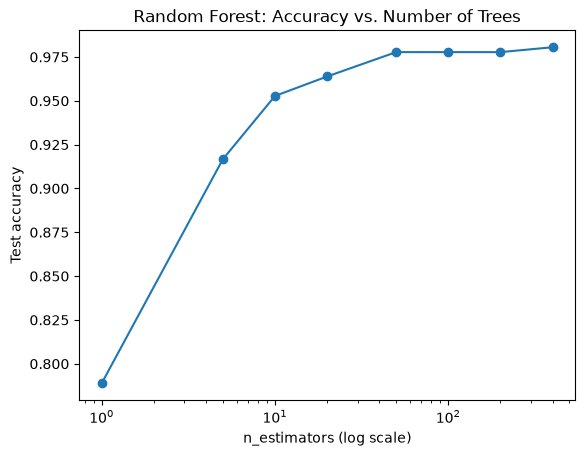

In [13]:

# Plot how test accuracy changes as the number of trees increases

plt.plot(n_trees_list, test_acc_rf, marker="o")

plt.xscale("log")
plt.xlabel("n_estimators (log scale)")
plt.ylabel("Test accuracy")
plt.title("Random Forest: Accuracy vs. Number of Trees")

plt.show()

Cell 7 — Plot Fit Time

- Explanation

We visualize the training cost of each Random Forest so we can compare additional training time with the accuracy gains.

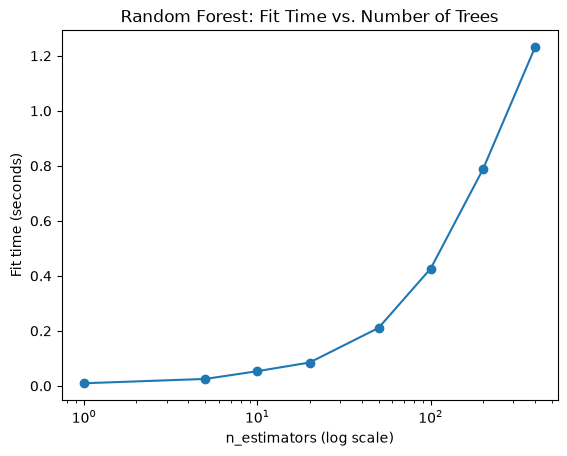

In [14]:

# Plot how Random Forest fitting time changes with the number of trees

plt.plot(n_trees_list, fit_times_rf, marker="o")

plt.xscale("log")
plt.xlabel("n_estimators (log scale)")
plt.ylabel("Fit time (seconds)")
plt.title("Random Forest: Fit Time vs. Number of Trees")

plt.show()

Practice 2 — n_estimators vs. fit time

Accuracy improves sharply up to n_estimators=50 (0.9778) and then essentially plateaus, gaining only 0.0028 more by 
n_estimators=400 — while fit time grows from 0.21s to 1.23s, nearly 6x slower for almost no benefit.

 This makes n_estimators=50 the practical sweet spot: past this point, additional trees cost real training time without meaningfully improving accuracy.